In [1]:
import os
print(os.listdir('/kaggle/input')) 
print(os.listdir('/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming'))

['datasets']
['release_artifacts', 'rf_jamming']


## Dataset Loading

In [2]:
import os
os.makedirs('/kaggle/working/intel', exist_ok=True)
!wget -q -P /kaggle/working/intel https://db.csail.mit.edu/labdata/connectivity.txt
!wget -q -P /kaggle/working/intel https://db.csail.mit.edu/labdata/mote_locs.txt
print(os.listdir('/kaggle/working/intel'))

['mote_locs.txt', 'connectivity.txt']


In [3]:
!head -3 /kaggle/working/intel/connectivity.txt
!head -3 /kaggle/working/intel/mote_locs.txt
!wc -l /kaggle/working/intel/*.txt

 1 0 0.75381767700138825
 1 1 0.00000000000000000000
 1 2 0.25790529076045041
1 21.5 23
2 24.5 20
3 19.5 19
 2972 /kaggle/working/intel/connectivity.txt
   54 /kaggle/working/intel/mote_locs.txt
 3026 total


In [4]:
import os, sys
for r, d, f in os.walk('/kaggle/input'):
    if any(x.endswith('.py') for x in f):
        print(r)

/kaggle/input/datasets/shourya2006/tactical-battlefield-simulation


In [5]:
sys.path.append('/kaggle/input/datasets/shourya2006/tactical-battlefield-simulation')  
!pip install simpy -q
import real_data_validation as rdv
import tactical_battlefield_sim as S
print('imports ok', len(S.CLUSTERS), 'clusters')

imports ok 6 clusters


In [6]:
import pandas as pd
ROOT = '/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming'
for sub in ['release_artifacts', 'rf_jamming']:
    p = os.path.join(ROOT, sub)
    print('\n##', sub, os.listdir(p)[:15])
    for d in os.listdir(p)[:6]:
        dp = os.path.join(p, d)
        if os.path.isdir(dp):
            print('  ', d, '->', len(os.listdir(dp)), 'items; first:', os.listdir(dp)[:4])
rdv.inspect_tree(os.path.join(ROOT, 'rf_jamming'), max_files=3)


## release_artifacts ['derived', 'metadata', 'release_file_inventory.csv', 'validation']
   derived -> 2 items; first: ['file_level_features.csv', 'file_level_features.parquet']
   metadata -> 2 items; first: ['data_dictionary.csv', 'manifest.csv']
   validation -> 8 items; first: ['dataset_composition_hierarchical.csv', 'metadata_warnings.csv', 'numeric_range_summary.csv', 'per_file_checks.csv']

## rf_jamming ['active_scan', 'passive_scan']
   active_scan -> 2 items; first: ['benign', 'malicious']
   passive_scan -> 2 items; first: ['benign', 'malicious']
/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming/rf_jamming: 0 files
/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming/rf_jamming/active_scan: 0 files
/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming/rf_jamming/active_scan/benign: 0 files
/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming/rf_jamming/active_scan/benign/background: 0 files
/kaggle/input/datasets/daniaherzalla/radio-frequen

In [7]:
def label_fn(path):
    p = path.lower()
    return ('passive' if 'passive_scan' in p else 'active',
            'jammed' if 'malicious' in p else 'benign')

In [8]:
WSJ = os.path.join(ROOT, 'rf_jamming')
wsj = rdv.load_wifispectraljam(WSJ, label_fn=label_fn, max_files=300)
print(wsj.groupby(['scan_mode','state']).size())
print(wsj.groupby(['scan_mode','state'])[['rssi_dbm','noise_floor_dbm']].mean().round(2))

scan_mode  state 
active     benign     12
           jammed      4
passive    benign    216
           jammed     68
dtype: int64
                  rssi_dbm  noise_floor_dbm
scan_mode state                            
active    benign    -87.67          -103.92
          jammed    -67.00          -102.00
passive   benign    -86.96          -101.98
          jammed    -84.45          -103.39


## Data Simulation

In [9]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from tactical_battlefield_sim import (load_region_data, build_tactical_partitions, audit_partitions,
                                      unsw_cols_map, FEATURES, CLUSTERS)
import real_data_validation as rdv

In [10]:
part_A, eval_A, raw_A = load_region_data('A', rows_per_client=20000, eval_rows=6000)
part_B, eval_B, raw_B = load_region_data('B', rows_per_client=20000, eval_rows=6000)
part_C, eval_C, raw_C = load_region_data('C', rows_per_client=20000, eval_rows=6000)

-> Region A / D1
-> Region A / D2
-> Region B / D3
-> Region B / D4
-> Region C / D5
-> Region C / D6


## Data Preprocessing

In [11]:
import numpy as np, pandas as pd
partitions = {**part_A, **part_B, **part_C}
df_eval = pd.concat([eval_A, eval_B, eval_C], ignore_index=True)
S.audit_partitions(partitions, df_eval)

D1 (REGION_A): n=20,000  benign=78.4%
    Benign               15,687  (78.44%)
    Gunshot_Fire          2,993  (14.96%)
    UAV_Intrusion         1,320  (6.60%)
D2 (REGION_A): n=20,000  benign=76.2%
    Benign               15,239  (76.20%)
    Hostile_Overflight    2,041  (10.21%)
    Gunshot_Fire          1,897  (9.49%)
    UAV_Intrusion           823  (4.12%)
D3 (REGION_B): n=20,000  benign=74.2%
    Benign               14,830  (74.15%)
    Truck_Mimicry         4,168  (20.84%)
    Infiltration          1,002  (5.01%)
D4 (REGION_B): n=20,000  benign=73.2%
    Benign               14,645  (73.22%)
    Armored_Incursion     3,782  (18.91%)
    Infiltration          1,573  (7.87%)
D5 (REGION_C): n=20,000  benign=77.7%
    Benign               15,531  (77.66%)
    RF_Jamming            3,258  (16.29%)
    Fence_Breach          1,211  (6.05%)
D6 (REGION_C): n=20,000  benign=67.4%
    Benign               13,482  (67.41%)
    Rogue_Emitter         3,456  (17.28%)
    RF_Jamming        

In [12]:
import os, numpy as np, pandas as pd

ROOT = '/kaggle/input/datasets/daniaherzalla/radio-frequency-jamming'
WSJ  = os.path.join(ROOT, 'rf_jamming')
INTEL = '/kaggle/working/intel'

def label_fn(path):
    p = path.lower()
    return ('passive' if 'passive_scan' in p else 'active',
            'jammed' if 'malicious' in p else 'benign')

raw_all = {**raw_A, **raw_B, **raw_C}
rawC = pd.concat([raw_all['D5'], raw_all['D6']], ignore_index=True)

print('== parameter audit')
print(rdv.parameter_audit(S.CLUSTERS).round(2).drop(columns='source').to_string(index=False))

shift = rdv.sim_jamming_shift(rawC)
print('\n== simulator jamming shift (Region C)')
print(shift.round(2).to_string(index=False))

paths = [os.path.join(r, f) for r, _, fs in os.walk(WSJ) for f in fs if f.lower().endswith('.csv')]
grp = {}
for p in paths:
    grp.setdefault(label_fn(p), []).append(p)
print('\nfiles per group:', {k: len(v) for k, v in grp.items()})

rng = np.random.default_rng(0)
rows = []
for (mode, state), ps in grp.items():
    for p in rng.choice(ps, min(100, len(ps)), replace=False):
        d = pd.read_csv(p, usecols=['rssi', 'noise'])
        rows.append(dict(scan_mode=mode, state=state, rssi_dbm=(d.rssi - 95).mean(), noise_floor_dbm=d.noise.mean()))
wsj_s = pd.DataFrame(rows)
print(wsj_s.groupby(['scan_mode', 'state']).size().to_string())

print('\n== real vs simulator (jammed minus benign, dB)')
print(rdv.jamming_comparison(shift, wsj_s).round(2).to_string(index=False))

il = rdv.load_intel_links(f'{INTEL}/connectivity.txt', f'{INTEL}/mote_locs.txt')
rows = [dict(source='Intel Lab (real)', **rdv.grey_zone_stats(il.p_success.values))]
rows += [dict(source=f'SIM {k}', **rdv.grey_zone_stats(rdv.sim_link_samples(c.radio).p_success.values))
         for k, c in S.CLUSTERS.items()]
grey = pd.DataFrame(rows)
print('\n== link grey zone')
print(grey.round(3).to_string(index=False))

== parameter audit
client region parameter  sim_value  measured_lo  measured_hi status
    D1      A     n_exp        2.1         1.95         2.31 inside
    D1      A  sigma_db        4.0         4.25         5.30   near
    D2      A     n_exp        2.3         1.95         2.31 inside
    D2      A  sigma_db        5.0         4.25         5.30 inside
    D3      B     n_exp        3.0         3.22         5.00   near
    D3      B  sigma_db        7.0         4.25        12.60 inside
    D4      B     n_exp        3.2         3.22         5.00   near
    D4      B  sigma_db        8.0         4.25        12.60 inside
    D5      C     n_exp        2.7         1.95         3.58 inside
    D5      C  sigma_db        6.0         4.25        12.60 inside
    D6      C     n_exp        2.9         1.95         3.58 inside
    D6      C  sigma_db        7.0         4.25        12.60 inside

== simulator jamming shift (Region C)
          sim_metric                                  mean

['sim_jamming_shift.csv', 'LIMITATIONS.txt', 'link_grey_zone.csv', 'parameter_audit.csv', 'jamming_comparison.csv', 'validation.png']


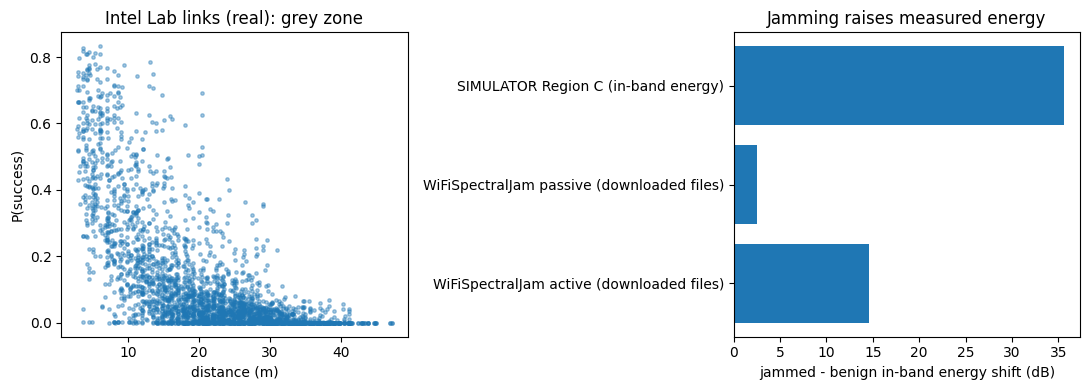

In [13]:
OUT = '/kaggle/working/validation_out'
os.makedirs(OUT, exist_ok=True)
rdv.parameter_audit(S.CLUSTERS).to_csv(f'{OUT}/parameter_audit.csv', index=False)
shift.to_csv(f'{OUT}/sim_jamming_shift.csv', index=False)
rdv.jamming_comparison(shift, wsj_s).to_csv(f'{OUT}/jamming_comparison.csv', index=False)
grey.to_csv(f'{OUT}/link_grey_zone.csv', index=False)
open(f'{OUT}/LIMITATIONS.txt', 'w').write(rdv.LIMITATIONS)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(il.dist_m, il.p_success, s=6, alpha=.4)
ax[0].set(xlabel='distance (m)', ylabel='P(success)', title='Intel Lab links (real): grey zone')
jc = rdv.jamming_comparison(shift, wsj_s)
ax[1].barh(jc.source, jc.energy_shift_db)
ax[1].set(xlabel='jammed - benign in-band energy shift (dB)', title='Jamming raises measured energy')
fig.tight_layout(); fig.savefig(f'{OUT}/validation.png', dpi=150)
print(os.listdir(OUT))

In [14]:
import os, json, numpy as np, pandas as pd
OUT = '/kaggle/working/tactical_data'
os.makedirs(OUT, exist_ok=True)

partitions = {**part_A, **part_B, **part_C}
raw_all    = {**raw_A, **raw_B, **raw_C}
df_eval    = pd.concat([eval_A, eval_B, eval_C], ignore_index=True)

for cid, df in partitions.items():
    df.to_csv(f'{OUT}/{cid}.csv', index=False)
    raw_all[cid].to_csv(f'{OUT}/{cid}_raw_physical.csv', index=False)
df_eval.to_csv(f'{OUT}/eval.csv', index=False)

dist = (pd.concat([df.assign(client=cid) for cid, df in partitions.items()])
          .groupby(['client', 'attack_type']).size().rename('rows').reset_index())
dist['share_of_client'] = dist.rows / dist.groupby('client').rows.transform('sum')
dist.round(4).to_csv(f'{OUT}/class_distribution.csv', index=False)

phys = {cid: [c for c in df.columns if c.startswith('phys_')] for cid, df in raw_all.items()}
json.dump(phys, open(f'{OUT}/logged_sensor_channels.json', 'w'), indent=1)
for cid, cols in phys.items():
    print(cid, len(cols), cols)
print(os.listdir(OUT))

D1 7 ['phys_aud_leq_db', 'phys_aud_peak_db', 'phys_aud_centroid_hz', 'phys_th_max_c', 'phys_las_speed_ms', 'phys_sat_changed_frac', 'phys_link_rssi_dbm']
D2 7 ['phys_aud_leq_db', 'phys_aud_peak_db', 'phys_aud_centroid_hz', 'phys_th_max_c', 'phys_las_speed_ms', 'phys_sat_changed_frac', 'phys_link_rssi_dbm']
D3 7 ['phys_geo_rms_um', 'phys_geo_peak_um', 'phys_geo_low_frac', 'phys_geo_high_frac', 'phys_mag_peak_nt', 'phys_pir_count', 'phys_link_rssi_dbm']
D4 7 ['phys_geo_rms_um', 'phys_geo_peak_um', 'phys_geo_low_frac', 'phys_geo_high_frac', 'phys_mag_peak_nt', 'phys_pir_count', 'phys_link_rssi_dbm']
D5 10 ['phys_pz_rms_mv', 'phys_pz_impulses', 'phys_amb_temp_c', 'phys_amb_rh', 'phys_amb_press_hpa', 'phys_rssi_dbm', 'phys_noise_floor_dbm', 'phys_snr_db', 'phys_unk_dbm', 'phys_link_rssi_dbm']
D6 10 ['phys_pz_rms_mv', 'phys_pz_impulses', 'phys_amb_temp_c', 'phys_amb_rh', 'phys_amb_press_hpa', 'phys_rssi_dbm', 'phys_noise_floor_dbm', 'phys_snr_db', 'phys_unk_dbm', 'phys_link_rssi_dbm']
['D1_r

## Data Partitioning between Clients

In [15]:
import os, copy, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

In [16]:
unsw_cols_map = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'dload',
    'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'rate'
]

DATA_DIR = None   

def find_data_dir():
    for base in ['/kaggle/working/tactical_data', 'tactical_data']:
        if os.path.exists(os.path.join(base, 'D1.csv')):
            return base
    for root, _, files in os.walk('/kaggle/input'):
        if 'D1.csv' in files and 'eval.csv' in files:
            return root
    raise FileNotFoundError("D1.csv / eval.csv not found. Generate the dataset first or set DATA_DIR.")

DATA_DIR = DATA_DIR or find_data_dir()
print("-> Loading tactical dataset from:", DATA_DIR)

client_ids = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
partitions = {cid: pd.read_csv(os.path.join(DATA_DIR, f'{cid}.csv')) for cid in client_ids}
df_eval = pd.read_csv(os.path.join(DATA_DIR, 'eval.csv'))
print({cid: len(df) for cid, df in partitions.items()}, '| eval:', len(df_eval))

-> Loading tactical dataset from: /kaggle/working/tactical_data
{'D1': 20000, 'D2': 20000, 'D3': 20000, 'D4': 20000, 'D5': 20000, 'D6': 20000} | eval: 18000


In [17]:
for name, df in list(partitions.items()) + [('EVAL', df_eval)]:
    missing = [c for c in unsw_cols_map + ['attack_type', 'label', 'source_domain'] if c not in df.columns]
    assert not missing, f"{name}: missing columns {missing}"
    feats = df[unsw_cols_map]
    assert np.isfinite(feats.to_numpy()).all(), f"{name}: NaN/inf in features"
    assert feats.min().min() >= 0.0 and feats.max().max() <= 1.0, f"{name}: feature outside [0,1]"
    assert set(df['label'].unique()) <= {0, 1}, f"{name}: label must be 0/1"
print("Feature contract OK for all partitions and the evaluation set.")

for df in list(partitions.values()) + [df_eval]:
    df[unsw_cols_map] = df[unsw_cols_map].astype(np.float32)
    df['label'] = df['label'].astype(int)

for cid in partitions:
    partitions[cid] = partitions[cid].sort_values(['node_id', 't_start']).reset_index(drop=True)

benign_train, local_val = {}, {}
for cid, df in partitions.items():
    ben = df[df['label'] == 0]
    benign_train[cid], local_val[cid] = train_test_split(ben, test_size=0.15, shuffle=False)  # keep time order
    print(cid, 'benign train', len(benign_train[cid]), '| benign val', len(local_val[cid]))

Feature contract OK for all partitions and the evaluation set.
D1 benign train 13333 | benign val 2354
D2 benign train 12953 | benign val 2286
D3 benign train 12605 | benign val 2225
D4 benign train 12448 | benign val 2197
D5 benign train 13201 | benign val 2330
D6 benign train 11459 | benign val 2023


In [18]:
research_paper_blueprint = {
    'D1': {'Total': 20000, 'Source': 'REGION_A', 'Counts': {'Benign': 15687, 'Gunshot_Fire': 2993, 'UAV_Intrusion': 1320}},
    'D2': {'Total': 20000, 'Source': 'REGION_A', 'Counts': {'Benign': 15239, 'Hostile_Overflight': 2041, 'Gunshot_Fire': 1897, 'UAV_Intrusion': 823}},
    'D3': {'Total': 20000, 'Source': 'REGION_B', 'Counts': {'Benign': 14830, 'Truck_Mimicry': 4168, 'Infiltration': 1002}},
    'D4': {'Total': 20000, 'Source': 'REGION_B', 'Counts': {'Benign': 14645, 'Armored_Incursion': 3782, 'Infiltration': 1573}},
    'D5': {'Total': 20000, 'Source': 'REGION_C', 'Counts': {'Benign': 15531, 'RF_Jamming': 3258, 'Fence_Breach': 1211}},
    'D6': {'Total': 20000, 'Source': 'REGION_C', 'Counts': {'Benign': 13482, 'Rogue_Emitter': 3456, 'RF_Jamming': 2686, 'Fence_Breach': 376}},
}
EVAL_TOTAL = 18000

system_wide_passed = True
for client_id, meta in research_paper_blueprint.items():
    client_df = partitions[client_id]
    actual_total, expected_total = len(client_df), meta['Total']
    size_status = "MATCHED" if actual_total == expected_total else "ERROR"
    print(f"AUDITING CLIENT PARTITION: {client_id} ({meta['Source']} Domain)")
    print(f" -> Total Flow Records: Actual={actual_total:<6} | Expected={expected_total:<6} -> {size_status}")
    if actual_total != expected_total: system_wide_passed = False
    if client_df['source_domain'].iloc[0] != meta['Source']: system_wide_passed = False

    actual_counts = client_df['attack_type'].value_counts()
    print(" -> Internal Threat Class Proportions Ledger:")
    for attack_cls, exp_count in meta['Counts'].items():
        act_count = actual_counts.get(attack_cls, 0)
        status = "MATCHED" if act_count == exp_count else "ERROR"
        print(f"    * [{status}] {attack_cls:<22} | Actual: {act_count:<6} ({act_count/actual_total*100:.2f}%) | Expected: {exp_count:<6} ({exp_count/expected_total*100:.2f}%)")
        if act_count != exp_count: system_wide_passed = False
    extra = set(actual_counts.index) - set(meta['Counts'])
    if extra:
        print("    !! unexpected classes:", extra); system_wide_passed = False
    print("-" * 65)

print(f"Eval Dataset Total Volume: Actual={len(df_eval)} | Expected={EVAL_TOTAL} -> {'MATCHED' if len(df_eval) == EVAL_TOTAL else 'ERROR'}")
print("Evaluation mix by region:", df_eval['source_domain'].value_counts().to_dict(),
      f"| benign share {(df_eval.label == 0).mean():.1%}")
if len(df_eval) != EVAL_TOTAL: system_wide_passed = False
print("AUDIT RESULT:", "PASSED" if system_wide_passed else "FAILED")

AUDITING CLIENT PARTITION: D1 (REGION_A Domain)
 -> Total Flow Records: Actual=20000  | Expected=20000  -> MATCHED
 -> Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                 | Actual: 15687  (78.44%) | Expected: 15687  (78.44%)
    * [MATCHED] Gunshot_Fire           | Actual: 2993   (14.96%) | Expected: 2993   (14.96%)
    * [MATCHED] UAV_Intrusion          | Actual: 1320   (6.60%) | Expected: 1320   (6.60%)
-----------------------------------------------------------------
AUDITING CLIENT PARTITION: D2 (REGION_A Domain)
 -> Total Flow Records: Actual=20000  | Expected=20000  -> MATCHED
 -> Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                 | Actual: 15239  (76.20%) | Expected: 15239  (76.20%)
    * [MATCHED] Hostile_Overflight     | Actual: 2041   (10.21%) | Expected: 2041   (10.21%)
    * [MATCHED] Gunshot_Fire           | Actual: 1897   (9.49%) | Expected: 1897   (9.49%)
    * [MATCHED] UAV_Intrusion          | Actual: 823    (4

## Baseline Model Pipeline of Research Paper

In [19]:
class FcNN_Baseline(nn.Module):
    """ 10-layer Dense Funnel Network for 13 compact features. """
    def __init__(self, input_dim=13): 
        super(FcNN_Baseline, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(),
            nn.Linear(8, 4), nn.ReLU(), nn.Linear(4, 2), nn.ReLU(),
            nn.Linear(2, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.network(x)

In [20]:
class OneD_CNN_Baseline(nn.Module):
    """ 1D-CNN configured for 13 compact features with explicit tensor return outputs. """
    def __init__(self, input_dim=13):
        super(OneD_CNN_Baseline, self).__init__()
        self.conv1 = nn.Sequential(nn.Conv1d(1, 16, kernel_size=2), nn.ReLU())
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(nn.Linear(12 * 16, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())
        
    def forward(self, x):
        if len(x.shape) == 2: x = x.unsqueeze(1)
        out = self.conv1(x)
        out = self.flatten(out)
        final_prediction = self.fc(out)
        return final_prediction

In [21]:
def client_update(model, train_df, local_epochs, lr, batch_size):
    model.train()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    X_data = torch.tensor(train_df[unsw_cols_map].values, dtype=torch.float32)
    y_data = torch.tensor(train_df['label'].values, dtype=torch.float32).unsqueeze(1)
    dataset = torch.utils.data.TensorDataset(X_data, y_data)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    for epoch in range(local_epochs):
        for batch_X, batch_y in loader:
            optimizer.zero_grad()
            pred = model(batch_X)
            loss = criterion(pred, batch_y)
            loss.backward()
            optimizer.step()
    return torch.cat([p.data.view(-1) for p in model.parameters()])

In [22]:
class AdaptiveServerOptimizer:
    """ Tracks parameter matrices across FedAvg, FedAdam, and FedYogi setups. """
    def __init__(self, model_shape, strategy="FedAvg", beta1=0.9, beta2=0.99, eta=0.1, tau=1e-3):
        self.strategy = strategy
        self.beta1 = beta1
        self.beta2 = beta2
        self.eta = eta
        self.tau = tau
        self.m_t = torch.zeros(model_shape)
        self.v_t = torch.ones(model_shape) * (tau ** 2)

    def aggregate(self, global_weights, client_updates_list, client_sizes):
        flat_global = torch.cat([p.data.view(-1) for p in global_weights.parameters()])
        
        if self.strategy == "FedAvg":
            total_n = sum(client_sizes)
            avg_update = torch.zeros_like(flat_global)
            for idx, c_weights in enumerate(client_updates_list):
                avg_update += (client_sizes[idx] / total_n) * c_weights
            return avg_update
        else:
            delta_t_list = [c_w - flat_global for c_w in client_updates_list]
            delta_t = torch.stack(delta_t_list).mean(dim=0)
            self.m_t = self.beta1 * self.m_t + (1.0 - self.beta1) * delta_t
            delta_sq = delta_t ** 2
            
            if self.strategy == "FedYogi":
                self.v_t = self.v_t - (1.0 - self.beta2) * delta_sq * torch.sign(self.v_t - delta_sq)
            elif self.strategy == "FedAdam":
                self.v_t = self.beta2 * self.v_t + (1.0 - self.beta2) * delta_sq
                
            return flat_global + self.eta * (self.m_t / (torch.sqrt(self.v_t) + self.tau))

In [23]:
def unpack_weights(model, flat_params):
    pointer = 0
    for p in model.parameters():
        num_elements = p.numel()
        p.data = flat_params[pointer:pointer + num_elements].view(p.shape)
        pointer += num_elements

In [24]:
def evaluate_global_model(model, eval_df):
    model.eval()
    X_eval = torch.tensor(eval_df[unsw_cols_map].values, dtype=torch.float32)
    y_eval = eval_df['label'].values
    with torch.no_grad():
        preds = model(X_eval).numpy().flatten()
        preds_binary = (preds >= 0.5).astype(int)
    return (
        accuracy_score(y_eval, preds_binary), 
        f1_score(y_eval, preds_binary, zero_division=0), 
        precision_score(y_eval, preds_binary, zero_division=0), 
        recall_score(y_eval, preds_binary, zero_division=0)
    )

In [27]:
def execute_federated_experiment(partitions_pool, eval_set, model_type="FcNN", strategy="FedAvg"):
    print(f"\nInitiating Loop: [{model_type}] Model running [{strategy}] Optimizer...")
    global_model = FcNN_Baseline() if model_type == "FcNN" else OneD_CNN_Baseline()
    total_params = sum(p.numel() for p in global_model.parameters())
    server = AdaptiveServerOptimizer(model_shape=total_params, strategy=strategy)
    client_ids = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
    
    for episode in range(1, 6):
        client_updates = []
        client_sizes = []
        for cid in client_ids:
            local_model = copy.deepcopy(global_model)
            episode_sample = partitions_pool[cid].sample(frac=1.0, replace=True)
            w_flat = client_update(local_model, episode_sample, local_epochs=5, lr=0.1, batch_size=64)
            client_updates.append(w_flat)
            client_sizes.append(len(episode_sample))
            
        new_global_flat = server.aggregate(global_model, client_updates, client_sizes)
        unpack_weights(global_model, new_global_flat)
        acc, f1, prec, rec = evaluate_global_model(global_model, eval_set)
        print(f" ➔ Episode {episode} Complete | Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

In [29]:
execute_federated_experiment(partitions, df_eval, model_type="FcNN", strategy="FedAvg")
execute_federated_experiment(partitions, df_eval, model_type="FcNN", strategy="FedAdam")
execute_federated_experiment(partitions, df_eval, model_type="FcNN", strategy="FedYogi")
execute_federated_experiment(partitions, df_eval, model_type="OneD_CNN", strategy="FedAvg")
execute_federated_experiment(partitions, df_eval, model_type="OneD_CNN", strategy="FedAdam")
execute_federated_experiment(partitions, df_eval, model_type="OneD_CNN", strategy="FedYogi")


Initiating Loop: [FcNN] Model running [FedAvg] Optimizer...
 ➔ Episode 1 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 2 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 3 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 4 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 5 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000

Initiating Loop: [FcNN] Model running [FedAdam] Optimizer...
 ➔ Episode 1 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 2 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 3 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 4 Complete | Accuracy: 0.7727 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000
 ➔ Episode 5 Complete | Accuracy: 0.7727 | F1: 0.0000 | Pr

## Advanced pipeline on the same tactical dataset

In [30]:
import math, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from torch.nn.utils import parameters_to_vector, vector_to_parameters
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score)

QUICK = globals().get('QUICK_TEST', False)
RUN_ABLATION = globals().get('RUN_ABLATION', True)     
RUN_EXTRAS = globals().get('RUN_EXTRAS', QUICK)        
RUN_ALL_BASELINE_STRATEGIES = globals().get('RUN_ALL_BASELINE_STRATEGIES', False)  

SEED = 42
SEEDS = (0,) if QUICK else (0, 1, 2)
FEATURES = list(unsw_cols_map)                        
CLIENT_IDS = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
CLIENT_DOMAIN = {c: partitions[c]['source_domain'].iloc[0] for c in CLIENT_IDS}
DOMAIN_CLIENTS = {}
for _c, _d in CLIENT_DOMAIN.items():
    DOMAIN_CLIENTS.setdefault(_d, []).append(_c)
REGIONS = sorted(DOMAIN_CLIENTS)
print('regions -> clients:', DOMAIN_CLIENTS, '| n_features:', len(FEATURES))

CFG = dict(
    fl_rounds=3 if QUICK else 20, fl_local_epochs=2, fl_lr=2e-3, fl_batch=256, fedprox_mu=0.01, max_rows=20000,
    ae_epochs=2 if QUICK else 15, ae_latent=6,
    guard_rounds=2 if QUICK else 20, guard_local_epochs=4, guard_windows=700,
    base_rounds=2 if QUICK else 5, base_local_epochs=1 if QUICK else 5, base_lr=1e-3, base_batch=64,
)

def set_seed(seed=SEED):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def flat_of(model):          return parameters_to_vector(model.parameters()).detach().clone()
def load_flat(model, flat):  vector_to_parameters(flat.detach().clone(), model.parameters())
def seg_sizes(model):        return [p.numel() for p in model.parameters()]

def binary_metrics(y, pred, score=None):
    out = dict(acc=accuracy_score(y, pred), f1=f1_score(y, pred, zero_division=0),
               prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0))
    if score is not None and len(np.unique(y)) > 1:
        out['auc'] = roc_auc_score(y, score); out['ap'] = average_precision_score(y, score)
    return out

def best_threshold(y, score, metric='f1'):
    """Pick the decision threshold on a VALIDATION set (never on the eval set)."""
    cands = np.unique(np.quantile(score, np.linspace(0.01, 0.99, 197)))
    f = (lambda t: f1_score(y, score >= t, zero_division=0)) if metric == 'f1' else (lambda t: accuracy_score(y, score >= t))
    return float(max(cands, key=f))

def per_class_table(df, preds):
    """Attack classes: recall. Benign: specificity (1 - false-alarm rate). preds = {name: 0/1 array}."""
    cls_arr = df['attack_type'].values; rows = []
    for cls in sorted(np.unique(cls_arr), key=lambda c: (c != 'Benign', c)):
        m = cls_arr == cls
        row = {'class': cls + (' (specificity)' if cls == 'Benign' else ' (recall)'), 'n': int(m.sum())}
        for name, p in preds.items():
            row[name] = round(float((p[m] == 0).mean() if cls == 'Benign' else (p[m] == 1).mean()), 4)
        rows.append(row)
    return pd.DataFrame(rows)

def per_region_table(df, preds):
    rows = []
    for reg in REGIONS:
        m = (df['source_domain'] == reg).values
        for name, p in preds.items():
            r = binary_metrics(df['label'].values[m], p[m])
            rows.append(dict(region=reg, model=name, **{k: round(v, 4) for k, v in r.items()}))
    return pd.DataFrame(rows)

regions -> clients: {'REGION_A': ['D1', 'D2'], 'REGION_B': ['D3', 'D4'], 'REGION_C': ['D5', 'D6']} | n_features: 13


In [31]:
VAL_FRAC, MIN_VAL_ATTACK, MIN_VAL_BENIGN = 0.10, 30, 100

def time_tail_split(df, frac=VAL_FRAC):
    """Last `frac` of every node's time series -> validation (no random mixing of neighbouring windows)."""
    d = df.sort_values(['node_id', 't_start'])
    from_end = d.groupby('node_id').cumcount(ascending=False)
    n_node = d.groupby('node_id')['t_start'].transform('size')
    is_val = from_end < np.ceil(n_node * frac)
    return d[~is_val], d[is_val]

parts_train, val_parts = {}, {}
for cid in CLIENT_IDS:
    tr, va = time_tail_split(partitions[cid])
    if (va['label'] == 1).sum() < MIN_VAL_ATTACK or (va['label'] == 0).sum() < MIN_VAL_BENIGN:
        tr, va = train_test_split(partitions[cid], test_size=VAL_FRAC, stratify=partitions[cid]['attack_type'], random_state=SEED)
        print(f'{cid}: chronological tail had too few attack/benign rows -> stratified random split used instead')
    parts_train[cid], val_parts[cid] = tr.reset_index(drop=True), va.reset_index(drop=True)

df_val = pd.concat(val_parts.values(), ignore_index=True)
val_fuse, val_guard = train_test_split(df_val, test_size=0.5, stratify=df_val['attack_type'], random_state=SEED)

def _fp(df): return pd.util.hash_pandas_object(df[FEATURES].round(5), index=False).values
_train_fp = np.concatenate([_fp(d) for d in parts_train.values()])
for _name, _d in (('validation', df_val), ('EVAL', df_eval)):
    _ov = np.isin(_fp(_d), _train_fp).mean()
    print(f'{_name:<10}: {_ov:.2%} of rows have an exact feature-vector twin in the training partitions')
print('  (a few % is normal for idle/quiet sensor rows; a large number would mean eval leaks into training)')

print('\ntrain rows per client:', {k: len(v) for k, v in parts_train.items()}, '| val:', len(df_val), '| eval:', len(df_eval))
print('attack share  train:', round(float(np.mean(np.concatenate([d["label"].values for d in parts_train.values()]))), 3),
      '| val:', round(float(df_val['label'].mean()), 3), '| eval:', round(float(df_eval['label'].mean()), 3))
_pos = float(df_eval['label'].mean())
print(f'\ntrivial references on EVAL:  always-benign acc={1-_pos:.4f} F1=0.0000 | always-attack acc={_pos:.4f} F1={2*_pos/(1+_pos):.4f}')

validation: 0.61% of rows have an exact feature-vector twin in the training partitions
EVAL      : 0.76% of rows have an exact feature-vector twin in the training partitions
  (a few % is normal for idle/quiet sensor rows; a large number would mean eval leaks into training)

train rows per client: {'D1': 17996, 'D2': 17996, 'D3': 17996, 'D4': 17996, 'D5': 17996, 'D6': 17996} | val: 12024 | eval: 18000
attack share  train: 0.259 | val: 0.22 | eval: 0.227

trivial references on EVAL:  always-benign acc=0.7727 F1=0.0000 | always-attack acc=0.2273 F1=0.3704


## Unsupervised spatial autoencoder per client (benign-only regional templates)

In [32]:
class SpatialAE(nn.Module):
    def __init__(self, input_dim=13, latent=6, kind='conv', channels=(8, 16)):
        super().__init__()
        self.input_dim, self.kind, self.c2 = input_dim, kind, channels[1]
        c1, c2 = channels
        if kind == 'conv':
            self.enc_conv = nn.Sequential(nn.Conv1d(1, c1, 3, padding=1), nn.ReLU(), nn.Conv1d(c1, c2, 3, padding=1), nn.ReLU())
            self.enc_fc = nn.Linear(c2 * input_dim, latent)
            self.dec_fc = nn.Linear(latent, c2 * input_dim)
            self.dec_conv = nn.Sequential(nn.ReLU(), nn.Conv1d(c2, c1, 3, padding=1), nn.ReLU(), nn.Conv1d(c1, 1, 3, padding=1))
        else:
            self.enc = nn.Sequential(nn.Linear(input_dim, 16), nn.ReLU(), nn.Linear(16, latent))
            self.dec = nn.Sequential(nn.Linear(latent, 16), nn.ReLU(), nn.Linear(16, input_dim))

    def encode(self, x):
        if self.kind == 'conv': return self.enc_fc(self.enc_conv(x.unsqueeze(1)).flatten(1))
        return self.enc(x)

    def decode(self, z):
        if self.kind == 'conv':
            return torch.sigmoid(self.dec_conv(self.dec_fc(z).view(-1, self.c2, self.input_dim))).squeeze(1)
        return torch.sigmoid(self.dec(z))

    def forward(self, x): return self.decode(self.encode(x))

def train_client_ae(client_df, kind='conv', latent=6, epochs=15, lr=2e-3, batch_size=512, max_rows=60000, seed=0):
    benign = client_df[client_df['label'] == 0]
    assert len(benign) > 0 and (benign['label'] == 0).all()
    if len(benign) > max_rows: benign = benign.sample(n=max_rows, random_state=seed)
    torch.manual_seed(seed)
    X = torch.tensor(benign[FEATURES].values, dtype=torch.float32)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X), batch_size=batch_size, shuffle=True)
    model = SpatialAE(len(FEATURES), latent, kind)
    opt, crit = optim.Adam(model.parameters(), lr=lr), nn.MSELoss()
    model.train()
    for _ in range(epochs):
        for (xb,) in loader:
            opt.zero_grad(); loss = crit(model(xb), xb); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def recon_errors(model, X_np, batch=8192):
    model.eval(); out = []
    for i in range(0, len(X_np), batch):
        xb = torch.tensor(X_np[i:i + batch], dtype=torch.float32)
        out.append(((model(xb) - xb) ** 2).mean(dim=1).numpy())
    return np.concatenate(out)

class IncrementalMemoryFilter:
    """Running mean/variance of the (log) reconstruction loss -> adaptive threshold mean + k*std."""
    def __init__(self, k=3.0, min_rate=0.001, use_log=True, min_std=0.05, freeze_on_flag=True, gate_z=2.5,
                 k_bounds=(2.0, 8.0), k_step=0.05):
        self.k, self.min_rate, self.use_log, self.min_std = k, min_rate, use_log, min_std
        self.freeze_on_flag, self.gate_z, self.k_bounds, self.k_step = freeze_on_flag, gate_z, k_bounds, k_step
        self.n, self.mean, self.var = 0, 0.0, 0.0

    def _t(self, e):
        e = np.asarray(e, dtype=np.float64)
        return np.log(e + 1e-8) if self.use_log else e

    def _update(self, x):
        self.n += 1
        rate = max(1.0 / self.n, self.min_rate)
        d = x - self.mean
        self.mean += rate * d
        self.var = (1.0 - rate) * (self.var + rate * d * d)

    @property
    def std(self): return max(math.sqrt(self.var), self.min_std)
    def threshold(self): return self.mean + self.k * self.std

    def warmup(self, errs):
        for x in self._t(errs): self._update(float(x))
        return self

    def score(self, errs): return (self._t(errs) - self.mean) / self.std

    def step(self, e):
        x = float(self._t(e)); z = (x - self.mean) / self.std; flag = z > self.k
        if (not self.freeze_on_flag) or z <= self.gate_z: self._update(x)
        return bool(flag), z

    def process(self, errs):
        flags, zs, thr = [], [], []
        for e in errs:
            thr.append(self.threshold()); f, z = self.step(e); flags.append(f); zs.append(z)
        return np.array(flags), np.array(zs), np.array(thr)

    def feedback(self, false_alarm):
        lo, hi = self.k_bounds
        self.k = min(hi, self.k + self.k_step) if false_alarm else max(lo, self.k - 0.1 * self.k_step)

def build_memory_filters(ae_bank, val_df, k=3.0):
    """Warm each client's filter on held-out BENIGN validation rows of its own region (rows the AE never trained on)."""
    flt = {}
    for cid in CLIENT_IDS:
        vb = val_df[(val_df['source_domain'] == CLIENT_DOMAIN[cid]) & (val_df['label'] == 0)]
        flt[cid] = IncrementalMemoryFilter(k=k).warmup(recon_errors(ae_bank[cid], vb[FEATURES].values.astype(np.float32)))
    return flt

def anomaly_z(df):
    """Per-flow anomaly z = best match over the regional templates of the flow's own region."""
    z = np.zeros(len(df)); X = df[FEATURES].values.astype(np.float32); dom = df['source_domain'].values
    for d, cids in DOMAIN_CLIENTS.items():
        m = dom == d
        if m.any(): z[m] = np.stack([filters[c].score(recon_errors(ae_bank[c], X[m])) for c in cids]).min(axis=0)
    return z

In [33]:
# ===== train the autoencoders + memory filters (unsupervised, benign-only)
t0 = time.time()
ae_bank = {cid: train_client_ae(parts_train[cid], kind='conv', latent=CFG['ae_latent'], epochs=CFG['ae_epochs'], seed=i)
           for i, cid in enumerate(CLIENT_IDS)}
print(f'trained {len(ae_bank)} client autoencoders ({time.time()-t0:.0f}s) | params each: {sum(p.numel() for p in ae_bank["D1"].parameters())}')

filters = build_memory_filters(ae_bank, val_fuse)
z_val = anomaly_z(val_fuse)
thr_ae = best_threshold(val_fuse['label'].values, z_val)
m_ae = binary_metrics(val_fuse['label'].values, z_val >= thr_ae, z_val)
print('AE + memory filter alone | val-tuned z threshold = %.2f | val metrics:' % thr_ae, {k: round(float(v), 4) for k, v in m_ae.items()})
_pos_v = float(val_fuse['label'].mean())
print(f'   reference: always-attack on val -> acc {_pos_v:.3f}, F1 {2*_pos_v/(1+_pos_v):.3f}.  AUC near 0.5 means the unsupervised score carries no signal.')

# same unsupervised detector on the EVAL set (threshold fixed from validation)
z_eval = anomaly_z(df_eval)
ae_eval = binary_metrics(df_eval['label'].values, z_eval >= thr_ae, z_eval)
print('AE + memory filter alone | EVAL:', {k: round(float(v), 4) for k, v in ae_eval.items()})

trained 6 client autoencoders (22s) | params each: 3559
AE + memory filter alone | val-tuned z threshold = -0.30 | val metrics: {'acc': 0.5399, 'f1': 0.3823, 'prec': 0.2712, 'rec': 0.6475, 'auc': 0.6128, 'ap': 0.3224}
   reference: always-attack on val -> acc 0.220, F1 0.361.  AUC near 0.5 means the unsupervised score carries no signal.
AE + memory filter alone | EVAL: {'acc': 0.5333, 'f1': 0.3773, 'prec': 0.2708, 'rec': 0.6221, 'auc': 0.6249, 'ap': 0.3887}


## GRU / LSTM temporal guard

In [34]:
FLAG_K = 3.0
GUARD_SCALE = np.array([10.0, 30.0, 10.0, 1.0])

def window_features(zw, k=FLAG_K):
    zc = np.clip(zw, -5, 30)
    return np.array([zc.mean(), zc.max(), zc.std(), (zc > k).mean()]) / GUARD_SCALE

def make_stream(z, y, n_windows=500, W=20, rng=None, p_burst=0.06, burst_len=(3, 8), p_truck=0.05, truck_q=0.97):
    """Chronological window stream. kind: 0 benign, 1 rare benign anomaly ("supply truck"), 2 attack burst."""
    rng = rng or np.random.default_rng(0)
    ben, att = np.where(y == 0)[0], np.where(y == 1)[0]
    cut = np.quantile(z[ben], truck_q)
    norm_idx, truck_idx = ben[z[ben] < cut], ben[z[ben] >= cut]
    def win(kind):
        if kind == 0: idx = rng.choice(norm_idx, W)
        elif kind == 1:
            m = int(rng.integers(W // 3, W // 2 + 1)); idx = np.concatenate([rng.choice(truck_idx, m), rng.choice(norm_idx, W - m)])
        else:
            m = int(rng.integers(W // 2, W + 1)); idx = np.concatenate([rng.choice(att, m), rng.choice(norm_idx, W - m)])
        return window_features(z[idx])
    F, kinds = [], []
    while len(F) < n_windows:
        r = rng.random()
        if r < p_burst and len(att):
            for _ in range(int(rng.integers(burst_len[0], burst_len[1] + 1))): F.append(win(2)); kinds.append(2)
        elif r < p_burst + p_truck and len(truck_idx):
            for _ in range(int(rng.integers(1, 3))): F.append(win(1)); kinds.append(1)
        else: F.append(win(0)); kinds.append(0)
    F, kinds = np.array(F[:n_windows]), np.array(kinds[:n_windows])
    return F, (kinds == 2).astype(np.float32), kinds

def to_sequences(F, lab, T=16, stride=4):
    idx = range(0, len(F) - T + 1, stride)
    return (np.stack([F[i:i + T] for i in idx]).astype(np.float32), np.stack([lab[i:i + T] for i in idx]).astype(np.float32))

class TemporalGuard(nn.Module):
    def __init__(self, in_dim=4, hidden=16, cell='gru'):
        super().__init__()
        self.rnn = (nn.GRU if cell == 'gru' else nn.LSTM)(in_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out).squeeze(-1)

def train_guard_local(model, X, Y, epochs=2, lr=3e-3, bs=64):
    model.train(); opt, crit = optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.tensor(X), torch.tensor(Y)), batch_size=bs, shuffle=True)
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()

def build_guard_shards(val_df, n_windows=700, W=20, T=16, seed=SEED):
    """One stream per client, built from held-out validation rows of that client's region."""
    rng, shards = np.random.default_rng(seed), []
    for dom, cids in DOMAIN_CLIENTS.items():
        dd = val_df[val_df['source_domain'] == dom].sample(frac=1, random_state=seed)
        for ix in np.array_split(np.arange(len(dd)), len(cids)):
            part = dd.iloc[ix]
            F, lab, _ = make_stream(anomaly_z(part), part['label'].values, n_windows, W, rng)
            shards.append(to_sequences(F, lab, T))
    return shards

def train_guard_federated(shards, rounds=10, local_epochs=2, cell='gru', seed=SEED):
    torch.manual_seed(seed); g = TemporalGuard(cell=cell)
    w = torch.tensor([len(s[0]) for s in shards], dtype=torch.float32); w = w / w.sum()
    for _ in range(rounds):
        flats = []
        for X, Y in shards:
            m = copy.deepcopy(g); train_guard_local(m, X, Y, local_epochs); flats.append(flat_of(m))
        load_flat(g, sum(wi * f for wi, f in zip(w, flats)))
    return g.eval()

@torch.no_grad()
def guard_predict(guard, F):
    return torch.sigmoid(guard(torch.tensor(F[None], dtype=torch.float32)))[0].numpy()

def evaluate_guard(guard, eval_df, n_windows=500, W=20, tau=0.5, seed=SEED + 1):
    rng, rows = np.random.default_rng(seed), []
    for dom in DOMAIN_CLIENTS:
        d = eval_df[eval_df['source_domain'] == dom].reset_index(drop=True)
        F, lab, kinds = make_stream(anomaly_z(d), d['label'].values, n_windows, W, rng)
        for name, pred in (('raw filter rule (>=50% flows flagged)', F[:, 3] >= 0.5), ('GRU/LSTM guard', guard_predict(guard, F) >= tau)):
            rows.append(dict(domain=dom, detector=name, win_acc=accuracy_score(lab, pred), win_f1=f1_score(lab, pred, zero_division=0),
                             attack_recall=pred[kinds == 2].mean(), benign_false_alarm=pred[kinds == 0].mean(),
                             rare_truck_false_alarm=pred[kinds == 1].mean() if (kinds == 1).any() else np.nan))
    return pd.DataFrame(rows).round(4)

In [35]:
t0 = time.time()
guard_shards = build_guard_shards(val_guard, n_windows=CFG['guard_windows'])
guard = train_guard_federated(guard_shards, rounds=CFG['guard_rounds'], local_epochs=CFG['guard_local_epochs'], cell='gru')
guard_table = evaluate_guard(guard, df_eval)
print(f'guard trained ({time.time()-t0:.0f}s)')
print(guard_table.to_string(index=False))
if (guard_table.loc[guard_table.detector == 'GRU/LSTM guard', 'attack_recall'] == 0).all():
    print('\nWARNING: the guard never fires on attack windows -> do not claim it works. It depends on the AE z-score carrying signal (see AUC above).')

guard trained (11s)
  domain                              detector  win_acc  win_f1  attack_recall  benign_false_alarm  rare_truck_false_alarm
REGION_A raw filter rule (>=50% flows flagged)    0.714     0.0            0.0                 0.0                     0.0
REGION_A                        GRU/LSTM guard    0.714     0.0            0.0                 0.0                     0.0
REGION_B raw filter rule (>=50% flows flagged)    0.708     0.0            0.0                 0.0                     0.0
REGION_B                        GRU/LSTM guard    0.708     0.0            0.0                 0.0                     0.0
REGION_C raw filter rule (>=50% flows flagged)    0.786     0.0            0.0                 0.0                     0.0
REGION_C                        GRU/LSTM guard    0.786     0.0            0.0                 0.0                     0.0



## INT8 stochastic quantizer, local DP, Byzantine-robust server, FedProx client, advanced federated loop

In [36]:
class Int8StochasticQuantizer:
    def __init__(self, segments, seed=0):
        self.segments, self.rng = list(segments), np.random.default_rng(seed)

    def quantize(self, vec):
        v = np.asarray(vec, dtype=np.float32)
        q = np.empty(v.size, dtype=np.int8); scales = np.empty(len(self.segments), dtype=np.float32); p = 0
        for i, n in enumerate(self.segments):
            seg = v[p:p + n]
            s = float(np.max(np.abs(seg))) / 127.0
            s = s if s > 0 else 1.0
            q[p:p + n] = np.clip(np.floor(seg / s + self.rng.random(n)), -127, 127).astype(np.int8)
            scales[i] = s; p += n
        return {'q': q, 'scales': scales}

    def dequantize(self, payload):
        out, p = np.empty(payload['q'].size, dtype=np.float32), 0
        for i, n in enumerate(self.segments):
            out[p:p + n] = payload['q'][p:p + n].astype(np.float32) * payload['scales'][i]; p += n
        return out

    @staticmethod
    def nbytes(payload): return payload['q'].nbytes + payload['scales'].nbytes

class LocalDPEngine:
    def __init__(self, clip_norm=1.0, noise_multiplier=0.0, bound_sigmas=3.0, seed=0):
        self.C, self.sigma, self.bound, self.rng = clip_norm, noise_multiplier, bound_sigmas, np.random.default_rng(seed)

    def privatize(self, delta):
        d = np.asarray(delta, dtype=np.float64)
        d = d * min(1.0, self.C / (np.linalg.norm(d) + 1e-12))
        if self.sigma > 0:
            noise = self.rng.normal(0.0, self.sigma * self.C, d.shape)
            if self.bound: lim = self.bound * self.sigma * self.C; noise = np.clip(noise, -lim, lim)
            d = d + noise
        return d.astype(np.float32)

    @staticmethod
    def _delta_of_eps(mu, eps):
        return norm.cdf(mu / 2 - eps / mu) - np.exp(eps) * norm.cdf(-mu / 2 - eps / mu)

    def epsilon(self, delta=1e-5, rounds=1):
        if self.sigma <= 0: return float('inf')
        mu = (2.0 / self.sigma) * math.sqrt(rounds)
        if self._delta_of_eps(mu, 200.0) > delta: return float('inf')
        lo, hi = 0.0, 200.0
        for _ in range(100):
            mid = (lo + hi) / 2
            if self._delta_of_eps(mu, mid) > delta: lo = mid
            else: hi = mid
        return hi

def trimmed_mean_np(D, beta=0.2):
    D = np.asarray(D, dtype=np.float64); n = D.shape[0]
    k = int(math.floor(beta * n))
    if n - 2 * k < 1: k = (n - 1) // 2
    return np.sort(D, axis=0)[k:n - k].mean(axis=0)

def geometric_median_np(D, weights=None, iters=200, tol=1e-7, eps=1e-8):
    D = np.asarray(D, dtype=np.float64)
    w = np.ones(len(D)) if weights is None else np.asarray(weights, dtype=np.float64)
    w = w / w.sum(); y = (w[:, None] * D).sum(axis=0)
    for _ in range(iters):
        a = w / np.maximum(np.linalg.norm(D - y, axis=1), eps)
        y_new = (a[:, None] * D).sum(axis=0) / a.sum()
        done = np.linalg.norm(y_new - y) <= tol * max(1.0, np.linalg.norm(y)); y = y_new
        if done: break
    return y

class AdaptiveServerOptimizerV2:
    STRATS = {'FedAvg', 'TrimmedMean', 'GeoMedian', 'FedAdam', 'FedYogi'}
    def __init__(self, model_shape, strategy='FedAvg', robust=None, trim_beta=0.2,
                 beta1=0.9, beta2=0.99, eta=0.1, tau=1e-3, server_lr=1.0):
        assert strategy in self.STRATS and robust in (None, 'TrimmedMean', 'GeoMedian')
        self.strategy, self.robust, self.trim_beta = strategy, robust, trim_beta
        self.beta1, self.beta2, self.eta, self.tau, self.server_lr = beta1, beta2, eta, tau, server_lr
        self.m_t = torch.zeros(model_shape); self.v_t = torch.ones(model_shape) * (tau ** 2)

    def _combine(self, D, sizes, rule):
        if rule == 'TrimmedMean': return trimmed_mean_np(D, self.trim_beta)
        if rule == 'GeoMedian':   return geometric_median_np(D, sizes)
        w = np.asarray(sizes, dtype=np.float64); w = w / w.sum()
        return (w[:, None] * D).sum(axis=0)

    def aggregate(self, global_model, client_deltas, client_sizes):
        flat_global = flat_of(global_model)
        D = np.stack([d.detach().cpu().numpy() for d in client_deltas]).astype(np.float64)
        rule = self.strategy if self.strategy in ('TrimmedMean', 'GeoMedian') else self.robust
        delta = torch.tensor(self._combine(D, client_sizes, rule), dtype=torch.float32)
        if self.strategy in ('FedAvg', 'TrimmedMean', 'GeoMedian'):
            return flat_global + self.server_lr * delta
        self.m_t = self.beta1 * self.m_t + (1.0 - self.beta1) * delta
        sq = delta ** 2
        if self.strategy == 'FedYogi': self.v_t = self.v_t - (1.0 - self.beta2) * sq * torch.sign(self.v_t - sq)
        else:                          self.v_t = self.beta2 * self.v_t + (1.0 - self.beta2) * sq
        return flat_global + self.eta * (self.m_t / (torch.sqrt(self.v_t) + self.tau))

class AdvFcNN(nn.Module):
    """No 2-unit ReLU bottleneck (dead-ReLU risk), LayerNorm (safe under FL), logits out."""
    def __init__(self, input_dim=13, hidden=(128, 64, 32)):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden: layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.GELU()]; prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_xy(df, domain_flag=False):
    """domain_flag=False -> exactly the baseline's 13 inputs. True -> + one-hot region (3 extra inputs)."""
    X = df[FEATURES].values.astype(np.float32)
    if domain_flag:
        X = np.concatenate([X] + [(df['source_domain'].values == r).astype(np.float32)[:, None] for r in REGIONS], axis=1)
    return torch.tensor(X), torch.tensor(df['label'].values.astype(np.float32)).unsqueeze(1)

def client_update_v2(model, global_flat, df, local_epochs=2, lr=2e-3, batch_size=256, mu=0.0, domain_flag=False):
    load_flat(model, global_flat); model.train()
    anchors = [p.detach().clone() for p in model.parameters()]
    X, y = make_xy(df, domain_flag)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    opt, crit = optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    for _ in range(local_epochs):
        for xb, yb in loader:
            opt.zero_grad(); loss = crit(model(xb), yb)
            if mu > 0: loss = loss + 0.5 * mu * sum(((p - a) ** 2).sum() for p, a in zip(model.parameters(), anchors))   # FedProx
            loss.backward(); opt.step()
    return flat_of(model) - global_flat

@torch.no_grad()
def predict_proba_adv(model, df, domain_flag=False, batch=16384):
    model.eval(); X, _ = make_xy(df, domain_flag)
    return np.concatenate([torch.sigmoid(model(X[i:i + batch])).numpy().ravel() for i in range(0, len(X), batch)])

def run_advanced_fl(parts, val_df, eval_df, strategy='FedAvg', robust=None, rounds=None, local_epochs=None, lr=None, batch_size=None,
                    mu=None, clip_norm=None, dp_sigma=0.01, quantize=True, byzantine=(), byz_scale=5.0, max_rows=None,
                    seed=SEED, domain_flag=False, verbose=True, tag='', track_eval=True):
    rounds = rounds or CFG['fl_rounds']; local_epochs = local_epochs or CFG['fl_local_epochs']
    lr = lr or CFG['fl_lr']; batch_size = batch_size or CFG['fl_batch']
    mu = CFG['fedprox_mu'] if mu is None else mu; max_rows = max_rows or CFG['max_rows']
    set_seed(seed)
    gm = AdvFcNN(input_dim=len(FEATURES) + (len(REGIONS) if domain_flag else 0))
    server = AdaptiveServerOptimizerV2(sum(p.numel() for p in gm.parameters()), strategy=strategy, robust=robust)
    dp = LocalDPEngine(clip_norm, dp_sigma, seed=seed) if clip_norm else None
    quant = Int8StochasticQuantizer(seg_sizes(gm), seed=seed) if quantize else None
    up_bytes = fp32_equiv = 0; history = []
    for r in range(1, rounds + 1):
        g_flat = flat_of(gm); deltas, sizes = [], []
        for cid in CLIENT_IDS:
            df = parts[cid].sample(n=min(max_rows, len(parts[cid])), replace=False, random_state=seed + r)
            d = client_update_v2(copy.deepcopy(gm), g_flat, df, local_epochs, lr, batch_size, mu, domain_flag).numpy()
            fp32_equiv += 4 * d.size
            if cid in byzantine:
                sent = -byz_scale * d; up_bytes += 4 * d.size
            else:
                if dp is not None: d = dp.privatize(d)
                if quant is not None:
                    payload = quant.quantize(d); up_bytes += quant.nbytes(payload); d = quant.dequantize(payload)
                else: up_bytes += 4 * d.size
                sent = d
            deltas.append(torch.tensor(sent, dtype=torch.float32)); sizes.append(len(df))
        load_flat(gm, server.aggregate(gm, deltas, sizes))
        p_val = predict_proba_adv(gm, val_df, domain_flag)
        h = dict(round=r, **{'val_' + k: round(float(v), 4) for k, v in binary_metrics(val_df['label'].values, p_val >= 0.5).items()})
        if track_eval:   
            p_t = predict_proba_adv(gm, eval_df, domain_flag)
            h.update({'eval_' + k: round(float(v), 4) for k, v in binary_metrics(eval_df['label'].values, p_t >= 0.5).items()})
        history.append(h)
        if verbose and (r % 4 == 0 or r == rounds): print(f'  [{tag}] round {r:>2} | val acc {h["val_acc"]:.4f} | val F1 {h["val_f1"]:.4f}')
    p_ev = predict_proba_adv(gm, eval_df, domain_flag)
    res = dict(model=gm, history=history, uplink_bytes=up_bytes, uplink_fp32_equiv=fp32_equiv, p_ev=p_ev,
               eps=(dp.epsilon(1e-5, rounds) if dp else None), domain_flag=domain_flag)
    res['eval'] = {k: float(v) for k, v in binary_metrics(eval_df['label'].values, p_ev >= 0.5, p_ev).items()}
    return res

## Advanced classifier: FedAvg + FedProx + INT8 (same 13 inputs as the baseline)

In [37]:
adv_runs = {}
for s in SEEDS:
    t0 = time.time()
    adv_runs[s] = run_advanced_fl(parts_train, val_fuse, df_eval, strategy='FedAvg', domain_flag=False, seed=s, tag=f'adv seed{s}')
    print(f'ADVANCED (FedAvg+FedProx+INT8) seed {s} | EVAL:', {k: round(v, 4) for k, v in adv_runs[s]['eval'].items()}, f'({time.time()-t0:.0f}s)')
r0 = adv_runs[SEEDS[0]]
print('\nuplink: %.1f KB sent vs %.1f KB if FP32  ->  %.1f%% saving' % (r0['uplink_bytes'] / 1e3, r0['uplink_fp32_equiv'] / 1e3,
      100 * (1 - r0['uplink_bytes'] / r0['uplink_fp32_equiv'])))

  [adv seed0] round  4 | val acc 0.8656 | val F1 0.7159
  [adv seed0] round  8 | val acc 0.8744 | val F1 0.7209
  [adv seed0] round 12 | val acc 0.8738 | val F1 0.7229
  [adv seed0] round 16 | val acc 0.8643 | val F1 0.7175
  [adv seed0] round 20 | val acc 0.8719 | val F1 0.7214
ADVANCED (FedAvg+FedProx+INT8) seed 0 | EVAL: {'acc': 0.8612, 'f1': 0.7127, 'prec': 0.673, 'rec': 0.7573, 'auc': 0.9226, 'ap': 0.739} (123s)
  [adv seed1] round  4 | val acc 0.8716 | val F1 0.7139
  [adv seed1] round  8 | val acc 0.8714 | val F1 0.7202
  [adv seed1] round 12 | val acc 0.8724 | val F1 0.7218
  [adv seed1] round 16 | val acc 0.8714 | val F1 0.7220
  [adv seed1] round 20 | val acc 0.8733 | val F1 0.7217
ADVANCED (FedAvg+FedProx+INT8) seed 1 | EVAL: {'acc': 0.8639, 'f1': 0.7165, 'prec': 0.6805, 'rec': 0.7565, 'auc': 0.92, 'ap': 0.725} (130s)
  [adv seed2] round  4 | val acc 0.8676 | val F1 0.7185
  [adv seed2] round  8 | val acc 0.8601 | val F1 0.7123
  [adv seed2] round 12 | val acc 0.8746 | val F

## Baseline re-run on the identical split (same 90% train, same eval, same seeds, same metrics incl. AUC)

In [38]:
@torch.no_grad()
def baseline_predict(model, df, batch=16384):
    model.eval(); X = torch.tensor(df[unsw_cols_map].values, dtype=torch.float32)
    return np.concatenate([model(X[i:i + batch]).numpy().ravel() for i in range(0, len(X), batch)])

def run_baseline(model_type='FcNN', strategy='FedAvg', seed=0, rounds=None, local_epochs=None, lr=None, batch_size=None,
                 train_parts=None, verbose=True):
    """Exactly the baseline notebook's loop (same models, client_update, AdaptiveServerOptimizer) but seeded, on parts_train,
    returning the model, per-round eval history and AUC/AP so it is directly comparable with the advanced runs."""
    rounds = rounds or CFG['base_rounds']; local_epochs = local_epochs or CFG['base_local_epochs']
    lr = lr or CFG['base_lr']; batch_size = batch_size or CFG['base_batch']; train_parts = train_parts or parts_train
    set_seed(seed)
    gm = FcNN_Baseline() if model_type == 'FcNN' else OneD_CNN_Baseline()
    n_params = sum(p.numel() for p in gm.parameters())
    server = AdaptiveServerOptimizer(model_shape=n_params, strategy=strategy)
    history = []
    for ep in range(1, rounds + 1):
        ups, sizes = [], []
        for cid in CLIENT_IDS:
            samp = train_parts[cid].sample(frac=1.0, replace=True, random_state=seed * 100 + ep)
            ups.append(client_update(copy.deepcopy(gm), samp, local_epochs, lr, batch_size)); sizes.append(len(samp))
        unpack_weights(gm, server.aggregate(gm, ups, sizes))
        p = baseline_predict(gm, df_eval)
        history.append(dict(round=ep, **{'eval_' + k: round(float(v), 4) for k, v in binary_metrics(df_eval['label'].values, p >= 0.5).items()}))
    p_ev = baseline_predict(gm, df_eval)
    ev = {k: float(v) for k, v in binary_metrics(df_eval['label'].values, p_ev >= 0.5, p_ev).items()}
    if verbose: print(f'  [{model_type}/{strategy}] seed {seed} final EVAL:', {k: round(v, 4) for k, v in ev.items()})
    return dict(model=gm, history=history, eval=ev, p_ev=p_ev, uplink_bytes=4 * n_params * len(CLIENT_IDS) * rounds)

base_cfgs = [('FcNN', 'FedAvg'), ('OneD_CNN', 'FedAvg')]
if RUN_ALL_BASELINE_STRATEGIES:
    base_cfgs += [(m, s) for m in ('FcNN', 'OneD_CNN') for s in ('FedAdam', 'FedYogi')]
base_runs = {}
for (mt, st) in base_cfgs:
    t0 = time.time()
    base_runs[(mt, st)] = {s: run_baseline(mt, st, seed=s) for s in SEEDS}
    print(f'{mt}/{st} done ({time.time()-t0:.0f}s)')

  [FcNN/FedAvg] seed 0 final EVAL: {'acc': 0.8634, 'f1': 0.7162, 'prec': 0.6787, 'rec': 0.758, 'auc': 0.9138, 'ap': 0.6704}
  [FcNN/FedAvg] seed 1 final EVAL: {'acc': 0.8534, 'f1': 0.7084, 'prec': 0.6464, 'rec': 0.7834, 'auc': 0.9175, 'ap': 0.6847}
  [FcNN/FedAvg] seed 2 final EVAL: {'acc': 0.8613, 'f1': 0.7214, 'prec': 0.6638, 'rec': 0.79, 'auc': 0.9195, 'ap': 0.685}
FcNN/FedAvg done (375s)
  [OneD_CNN/FedAvg] seed 0 final EVAL: {'acc': 0.8649, 'f1': 0.716, 'prec': 0.6855, 'rec': 0.7492, 'auc': 0.9192, 'ap': 0.7081}
  [OneD_CNN/FedAvg] seed 1 final EVAL: {'acc': 0.8641, 'f1': 0.7128, 'prec': 0.6856, 'rec': 0.7424, 'auc': 0.9178, 'ap': 0.7006}
  [OneD_CNN/FedAvg] seed 2 final EVAL: {'acc': 0.8527, 'f1': 0.6537, 'prec': 0.702, 'rec': 0.6116, 'auc': 0.919, 'ap': 0.7026}
OneD_CNN/FedAvg done (332s)


## Side-by-side comparison

In [39]:
def _fmt(vals): a = np.asarray(vals, dtype=float); return f'{a.mean():.4f} ± {a.std():.4f}'
def summarize(name, runs, domain_note=''):
    ev = pd.DataFrame([r['eval'] for r in runs.values()])
    row = {'pipeline': name, **{m: _fmt(ev[m]) for m in ['acc', 'f1', 'prec', 'rec', 'auc', 'ap']}}
    row['uplink MB/run'] = round(float(np.mean([r['uplink_bytes'] for r in runs.values()])) / 1e6, 3)
    return row

rows = []
for (mt, st), runs in base_runs.items(): rows.append(summarize(f'BASELINE {mt} {st}', runs))
rows.append(summarize('ADVANCED  AdvMLP FedAvg+FedProx+INT8', adv_runs))
_pos = float(df_eval['label'].mean())
rows.append({'pipeline': 'ref: always-benign', 'acc': f'{1-_pos:.4f}', 'f1': '0.0000', 'prec': '0.0000', 'rec': '0.0000', 'auc': '0.5000', 'ap': f'{_pos:.4f}', 'uplink MB/run': 0})
rows.append({'pipeline': 'ref: always-attack', 'acc': f'{_pos:.4f}', 'f1': f'{2*_pos/(1+_pos):.4f}', 'prec': f'{_pos:.4f}', 'rec': '1.0000', 'auc': '0.5000', 'ap': f'{_pos:.4f}', 'uplink MB/run': 0})
comparison = pd.DataFrame(rows)
print(f'EVAL set: {len(df_eval)} rows, attack share {_pos:.1%} | seeds={list(SEEDS)} | mean ± std over seeds, FINAL round\n')
print(comparison.to_string(index=False))

for mt in ('FcNN', 'OneD_CNN'):
    if (mt, 'FedAvg') in base_runs:
        diffs = [adv_runs[s]['eval']['f1'] - base_runs[(mt, 'FedAvg')][s]['eval']['f1'] for s in SEEDS]
        print(f'F1 gain over baseline {mt} FedAvg per seed:', [round(d, 4) for d in diffs])

s0 = SEEDS[0]
preds = {'base FcNN': (base_runs[('FcNN', 'FedAvg')][s0]['p_ev'] >= 0.5).astype(int),
         'base CNN':  (base_runs[('OneD_CNN', 'FedAvg')][s0]['p_ev'] >= 0.5).astype(int),
         'advanced':  (adv_runs[s0]['p_ev'] >= 0.5).astype(int)}
print('\n== per region (seed %d) ==' % s0); print(per_region_table(df_eval, preds).to_string(index=False))
print('\n== per attack class (seed %d) ==' % s0); per_class = per_class_table(df_eval, preds); print(per_class.to_string(index=False))

EVAL set: 18000 rows, attack share 22.7% | seeds=[0, 1, 2] | mean ± std over seeds, FINAL round

                            pipeline             acc              f1            prec             rec             auc              ap  uplink MB/run
                BASELINE FcNN FedAvg 0.8594 ± 0.0043 0.7153 ± 0.0054 0.6630 ± 0.0132 0.7772 ± 0.0138 0.9169 ± 0.0023 0.6800 ± 0.0068          0.443
            BASELINE OneD_CNN FedAvg 0.8606 ± 0.0055 0.6942 ± 0.0286 0.6910 ± 0.0078 0.7011 ± 0.0633 0.9187 ± 0.0006 0.7038 ± 0.0032          0.751
ADVANCED  AdvMLP FedAvg+FedProx+INT8 0.8632 ± 0.0014 0.7158 ± 0.0023 0.6779 ± 0.0035 0.7582 ± 0.0018 0.9211 ± 0.0011 0.7307 ± 0.0060          1.520
                  ref: always-benign          0.7727          0.0000          0.0000          0.0000          0.5000          0.2273          0.000
                  ref: always-attack          0.2273          0.3704          0.2273          1.0000          0.5000          0.2273          0.000
F1 gain over ba

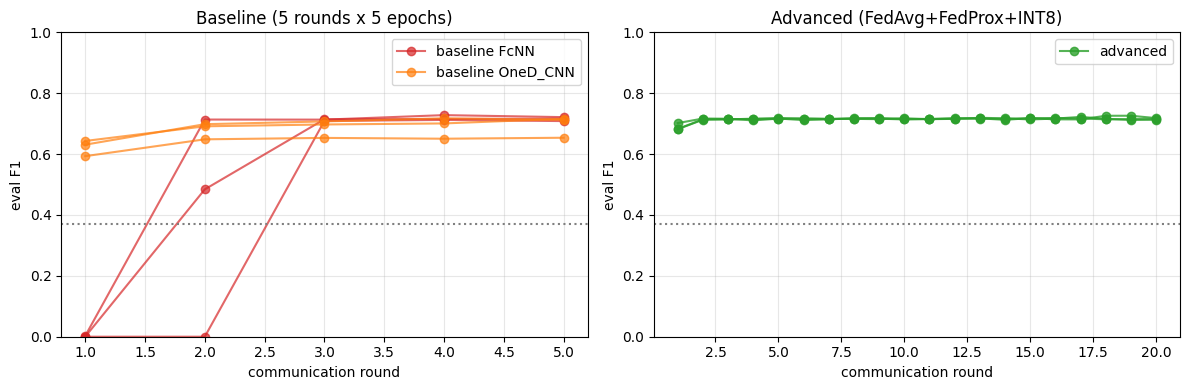

In [40]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (mt, st), runs in base_runs.items():
    if st != 'FedAvg': continue
    for s, r in runs.items():
        ax[0].plot([h['round'] for h in r['history']], [h['eval_f1'] for h in r['history']], marker='o', alpha=.7,
                   label=f'baseline {mt}' if s == SEEDS[0] else None, color='tab:red' if mt == 'FcNN' else 'tab:orange')
for s, r in adv_runs.items():
    ax[1].plot([h['round'] for h in r['history']], [h['eval_f1'] for h in r['history']], marker='o', alpha=.8, color='tab:green',
               label='advanced' if s == SEEDS[0] else None)
for a, t in zip(ax, ('Baseline (5 rounds x 5 epochs)', 'Advanced (FedAvg+FedProx+INT8)')):
    a.set(title=t, xlabel='communication round', ylabel='eval F1', ylim=(0, 1)); a.axhline(2*_pos/(1+_pos), ls=':', c='gray'); a.legend(); a.grid(alpha=.3)
fig.tight_layout(); plt.show()